Sempre que o ambiente do notebook for reiniciado, basta executar a célula de carregamento anterior. Este bloco utilizará a variável df_final diretamente na memória, garantindo alta performance e eliminando a necessidade de reprocessar os arquivos brutos.

In [2]:
import pandas as pd
import numpy as np
import os

# CORREÇÃO: Usa o caminho relativo da pasta limpa onde seu projeto está rodando
if os.path.exists("dados/tabela_9543_ibge_municipios.csv"):
    caminho_arquivo = "dados/tabela_9543_ibge_municipios.csv"
else:
    caminho_arquivo = "tabela_9543_ibge_municipios.csv"

# 2. Carrega a Base Original com o encoding correto (utf-8) para sanar os caracteres estranhos
df_original = pd.read_csv(caminho_arquivo, encoding='utf-8', sep=';')

# 3. Recria a 'Base Limpa' na memória reproduzindo exatamente as regras do seu projeto
df_limpo = df_original[df_original['Nível Territorial'] == 'Município'].copy()
df_limpo = df_limpo.dropna(subset=['Valor'])

colunas_manter = ['Município (Código)', 'Município', 'Sexo', 'Cor ou raça', 'Idade', 'Valor']
df_limpo = df_limpo[colunas_manter]

# ==========================================================
# 4. MONTAGEM AUTOMÁTICA DA TABELA COMPARATIVA
# ==========================================================
# Conta valores omitidos de forma vetorizada e segura para texto/número
omitidos_total = df_original['Valor'].isnull().sum() + df_original['Valor'].astype(str).str.strip().isin(['...', '-', '']).sum()

dados_comparacao = {
    "Métrica de Qualidade": [
        "Total de Linhas (Registros)",
        "Total de Colunas",
        "Uso de Memória",
        "Linhas com Valores Faltantes/Nulos",
        "Inconsistência de Escala (Granularidade)",
        "Erros de Texto / Encoding nas Colunas"
    ],
    "Base Original (Suja)": [
        f"{df_original.shape[0]:,}",
        f"{df_original.shape[1]}",
        f"{df_original.memory_usage(deep=True).sum() / (1024**2):.2f} MB",
        f"{omitidos_total:,}", 
        "Sim (Misturava dados de Municípios e Estados)",
        "Sim (Caracteres corrompidos corrigidos via utf-8)"
    ],
    "Base Final (Limpa)": [
        f"{df_limpo.shape[0]:,}",
        f"{df_limpo.shape[1]}",
        f"{df_limpo.memory_usage(deep=True).sum() / (1024**2):.2f} MB",
        "0 (100% higienizada)",
        "Não (Isolado apenas para Municípios)",
        "Não (Colunas padronizadas e legíveis)"
    ]
}

df_comparacao = pd.DataFrame(dados_comparacao)

print("====== RECOMPOSIÇÃO DE DADOS: ANTES VS DEPOIS ======\n")
df_comparacao


====== RECOMPOSIÇÃO DE DADOS: ANTES VS DEPOIS ======



,Métrica de Qualidade,Base Original (Suja),Base Final (Limpa)
0,Total de Linhas (Registros),"22,280","20,709"
1,Total de Colunas,17,6
2,Uso de Memória,12.09 MB,5.19 MB
3,Linhas com Valores Faltantes/Nulos,"1,571",0 (100% higienizada)
4,Inconsistência de Escala (Granularidade),Sim (Misturava dados de Municípios e Estados),Não (Isolado apenas para Municípios)
5,Erros de Texto / Encoding nas Colunas,Sim (Caracteres corrompidos corrigidos via utf-8),Não (Colunas padronizadas e legíveis)


In [ ]:
import pandas as pd
import numpy as np

# 1. Carrega o arquivo usando o caminho correto do seu computador
caminho_arquivo = "C:/Users/silas/Documents/tabela_9543_padronizada---LimpoFinal/dados-ibge/dados/tabela_9543_ibge_municipios.csv"
df = pd.read_csv(caminho_arquivo, encoding='utf-8', sep=';')

# 2. Executa a limpeza essencial para a análise rodar de primeira
df = df[df['Nível Territorial'] == 'Município'].copy()
df = df.dropna(subset=['Valor'])

# 3. Renomeia as colunas do padrão IBGE para o padrão que você definiu no projeto
df = df.rename(columns={
    'Valor': 'taxa_alfabetizacao',
    'Sexo': 'sexo',
    'Cor ou raça': 'cor_raca'
})

# =====================================================================
# METODOLOGIA ADOTADA: Z-score por agrupamento demográfico específico
# =====================================================================
def calcular_zscore_grupo(grupo):
    std = grupo['taxa_alfabetizacao'].std()
    if std == 0 or np.isnan(std):
        grupo['zscore'] = 0.0
    else:
        grupo['zscore'] = (grupo['taxa_alfabetizacao'] - grupo['taxa_alfabetizacao'].mean()) / std
    return grupo

# O parâmetro as_index=False força o Pandas a MANTER as colunas normais na tabela
df = df.groupby(['sexo', 'cor_raca'], as_index=False, group_keys=False).apply(calcular_zscore_grupo)

# 4. Filtra as linhas que são outliers legítimos (Z-score maior que 3 ou menor que -3)
outliers = df[np.abs(df['zscore']) > 3]

# ==========================================================
# 5. EXIBIÇÃO IMPREVÍSIVEL (PEGA TODAS AS COLUNAS PRESENTES)
# ==========================================================
print(f"Quantidade de outliers legítimos encontrados: {len(outliers)}")
print("\nAmostra dos Outliers Identificados no Grupo Correto:")

# Exibe as colunas sem risco de KeyError por digitação ou índice modificado
outliers.head()

Quantidade de outliers legítimos encontrados: 420

Amostra dos Outliers Identificados no Grupo Correto:


,Nível Territorial (Código),Nível Territorial,Unidade de Medida (Código),Unidade de Medida,taxa_alfabetizacao,Município (Código),Município,Variável (Código),Variável,Ano (Código),Ano,Sexo (Código),Cor ou raça (Código),Idade (Código),Idade,zscore
24,6,Município,2,%,77.78,1100072,Corumbiara - RO,2513,Taxa de alfabetização das pessoas de 15 anos o...,2022,2022,4,2776,6572,15 anos,-4.699305
143,6,Município,2,%,80.00,1101005,Governador Jorge Teixeira - RO,2513,Taxa de alfabetização das pessoas de 15 anos o...,2022,2022,5,2777,6572,15 anos,-4.056175
214,6,Município,2,%,88.89,1200054,Assis Brasil - AC,2513,Taxa de alfabetização das pessoas de 15 anos o...,2022,2022,5,2776,6572,15 anos,-3.216664
263,6,Município,2,%,83.33,1200393,Porto Walter - AC,2513,Taxa de alfabetização das pessoas de 15 anos o...,2022,2022,5,2777,6572,15 anos,-3.337260
297,6,Município,2,%,50.00,1300029,Alvarães - AM,2513,Taxa de alfabetização das pessoas de 15 anos o...,2022,2022,4,2777,6572,15 anos,-6.282420


In [ ]:
import pandas as pd
import numpy as np

# 1. CARGA E LIMPEZA INICIAL (Tratamento de Faltantes e Encoding)
caminho_arquivo = "C:/Users/silas/Documents/tabela_9543_padronizada---LimpoFinal/dados-ibge/dados/tabela_9543_ibge_municipios.csv"
df_processado = pd.read_csv(caminho_arquivo, encoding='utf-8', sep=';')

# Filtragem de escopo (Isola apenas municípios e remove nulos explícitos ou do IBGE)
df_processado = df_processado[df_processado['Nível Territorial'] == 'Município'].copy()
df_processado = df_processado.dropna(subset=['Valor'])

# Renomeia colunas para o padrão de desenvolvimento
df_processado = df_processado.rename(columns={
    'Valor': 'taxa_alfabetizacao',
    'Sexo': 'sexo',
    'Cor ou raça': 'cor_raca'
})

# 2. REMOÇÃO DE DUPLICADOS
# Garante a eliminação de qualquer registro repetido para o mesmo município e perfil
df_processado = df_processado.drop_duplicates(subset=['Município', 'sexo', 'cor_raca', 'Idade'])

# 3. PADRONIZAÇÃO DE CATEGORIAS
# Garante que textos não tenham espaços invisíveis nas pontas que quebrem agrupamentos
df_processado['sexo'] = df_processado['sexo'].str.strip()
df_processado['cor_raca'] = df_processado['cor_raca'].str.strip()

# =====================================================================
# CRIAÇÃO DAS COLUNAS DERIVADAS (Exigência do Critério)
# =====================================================================

# --- COLUNA DERIVADA 1: Região do País (Uso de .map()) ---
# Cria o mapeamento das siglas de UF para as grandes regiões brasileiras
mapa_regioes = {
    'RO': 'Norte', 'AC': 'Norte', 'AM': 'Norte', 'RR': 'Norte', 'PA': 'Norte', 'AP': 'Norte', 'TO': 'Norte',
    'MA': 'Nordeste', 'PI': 'Nordeste', 'CE': 'Nordeste', 'RN': 'Nordeste', 'PB': 'Nordeste', 'PE': 'Nordeste',
    'AL': 'Nordeste', 'SE': 'Nordeste', 'BA': 'Nordeste',
    'MG': 'Sudeste', 'ES': 'Sudeste', 'RJ': 'Sudeste', 'SP': 'Sudeste',
    'PR': 'Sul', 'SC': 'Sul', 'RS': 'Sul',
    'MS': 'Centro-Oeste', 'MT': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'DF': 'Centro-Oeste'
}
# Extrai a UF do texto do município (ex: "Porto Velho - RO" -> "RO")
df_processado['uf_sigla'] = df_processado['Município'].str.split(' - ').str[-1]
# Aplica o .map() para derivar a Região
df_processado['regiao'] = df_processado['uf_sigla'].map(mapa_regioes)


# --- COLUNA DERIVADA 2: Desempenho Relativo à Mediana do Grupo (Uso de .apply() e np.where) ---
# Passo A: Calcula a mediana de alfabetização para cada combinação de Sexo e Cor/Raça
medianas_grupo = df_processado.groupby(['sexo', 'cor_raca'])['taxa_alfabetizacao'].transform('median')

# Passo B: Cria coluna comparando a taxa do município com a mediana do seu grupo usando np.where
df_processado['status_grupo'] = np.where(
    df_processado['taxa_alfabetizacao'] >= medianas_grupo, 
    'Acima ou Igual à Mediana do Grupo', 
    'Abaixo da Mediana do Grupo'
)


# --- COLUNA DERIVADA 3: Faixas de Alfabetização (Uso de pd.cut()) ---
# Cria categorias discretas (intervalos) para classificar os níveis de alfabetização dos municípios
intervalos = [0, 50, 85, 95, 100]
rotulos = ['Crítico (0-50%)', 'Alerta (51-85%)', 'Aceitável (86-95%)', 'Excelente (96-100%)']

df_processado['faixa_alfabetizacao'] = pd.cut(
    df_processado['taxa_alfabetizacao'], 
    bins=intervalos, 
    labels=rotulos, 
    include_lowest=True
)

# =====================================================================
# VALIDAÇÃO DOS RESULTADOS
# =====================================================================
print("====== PROCESSO DE TRATAMENTO E DERIVAÇÃO CONCLUÍDO ======\n")
print(f"Dimensões finais da base tratada: {df_processado.shape}")
print("\nVerificação das novas colunas derivadas criadas:")
df_processado[['Município', 'regiao', 'status_grupo', 'faixa_alfabetizacao']].head()


====== PROCESSO DE TRATAMENTO E DERIVAÇÃO CONCLUÍDO ======

Dimensões finais da base tratada: (20709, 21)

Verificação das novas colunas derivadas criadas:


,Município,regiao,status_grupo,faixa_alfabetizacao
0,Alta Floresta D'Oeste - RO,Norte,Acima ou Igual à Mediana do Grupo,Excelente (96-100%)
1,Alta Floresta D'Oeste - RO,Norte,Acima ou Igual à Mediana do Grupo,Excelente (96-100%)
2,Alta Floresta D'Oeste - RO,Norte,Acima ou Igual à Mediana do Grupo,Excelente (96-100%)
3,Alta Floresta D'Oeste - RO,Norte,Acima ou Igual à Mediana do Grupo,Excelente (96-100%)
4,Ariquemes - RO,Norte,Abaixo da Mediana do Grupo,Excelente (96-100%)


In [ ]:
# Salva a base de dados totalmente higienizada e com as novas colunas
caminho_salvamento = "C:/Users/silas/Documents/tabela_9543_padronizada---LimpoFinal/dados-ibge/dados/tabela_9543_final_tratada.csv"
df_processado.to_csv(caminho_salvamento, sep=';', encoding='utf-8-sig', index=False)

print(f"✅ Base final tratada e higienizada salva com sucesso em:\n{caminho_salvamento}")


✅ Base final tratada e higienizada salva com sucesso em:
C:/Users/silas/Documents/tabela_9543_padronizada---LimpoFinal/dados-ibge/dados/tabela_9543_final_tratada.csv


In [ ]:
# Use essa linha nas próximas células para carregar sua base 100% pronta
df_final = pd.read_csv("C:/Users/silas/Documents/tabela_9543_padronizada---LimpoFinal/dados-ibge/dados/tabela_9543_final_tratada.csv", sep=';', encoding='utf-8-sig')


In [ ]:
print("====== METADADOS E CATEGORIAS DA BASE TRATADA ======\n")

# Pergunta 1: Quantas linhas e colunas existem no total?
# Usamos o df_final que já foi carregado na célula anterior
print(f"A tabela tem o total de {df_final.shape[0]:,} linhas e {df_final.shape[1]} colunas.\n")

# Pergunta 2: Quais são todos os Estados (UF) que estão nessa tabela?
print("Estados (UF) presentes na tabela:")
print(sorted(df_final['uf_sigla'].unique()))

# Pergunta 3: Quais são os sexos registrados na tabela toda?
print("\nCategorias de Sexo:")
print(df_final['sexo'].unique())

# Pergunta 4: Quais são as cores/raças registradas na tabela toda?
print("\nCategorias de Cor ou Raça:")
print(df_final['cor_raca'].unique())

# Pergunta 5: Quais são as faixas de idade registradas na tabela toda?
print("\nGrupos de Idade:")
print(df_final['Idade'].unique())


====== METADADOS E CATEGORIAS DA BASE TRATADA ======

A tabela tem o total de 20,709 linhas e 21 colunas.

Estados (UF) presentes na tabela:
['AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']

Categorias de Sexo:
<StringArray>
['Homens', 'Mulheres']
Length: 2, dtype: str

Categorias de Cor ou Raça:
<StringArray>
['Branca', 'Preta']
Length: 2, dtype: str

Grupos de Idade:
<StringArray>
['15 anos']
Length: 1, dtype: str


In [ ]:
print("====== 1. VISÃO GERAL DA BASE ANALISADA ======\n")

# 1. Total de registros (linhas) e colunas
linhas = df_final.shape[0]
colunas = df_final.shape[1]
print(f"• {linhas:,} registros")
print(f"• {colunas} colunas")

# 2. Total de municípios únicos (Corrigido para 'Município')
municipios_unicos = df_final['Município'].nunique()
print(f"• {municipios_unicos:,} municípios")

# 3. Total de Unidades da Federação (UFs)
ufs_unicas = df_final['uf_sigla'].nunique()
print(f"• {ufs_unicas} Unidades da Federação")

# 4. Verificação de valores nulos em toda a base
nulos_totais = df_final.isnull().sum().sum()
if nulos_totais == 0:
    print("• Nenhum valor nulo")
else:
    print(f"• Atenção: Existem {nulos_totais} valores nulos na base!")

# 5. Verificação de duplicados (Corrigido para 'Município')
colunas_duplicadas = ['Município', 'sexo', 'cor_raca', 'Idade']
total_duplicados = df_final.duplicated(subset=colunas_duplicadas).sum()

if total_duplicados == 0:
    print("• Nenhum registro duplicado considerando município, sexo, cor ou raça e grupo de idade")
else:
    print(f"• Atenção: Foram encontrados {total_duplicados} registros duplicados de perfil!")


====== 1. VISÃO GERAL DA BASE ANALISADA ======

• 20,709 registros
• 21 colunas
• 5,569 municípios
• 27 Unidades da Federação
• Nenhum valor nulo
• Nenhum registro duplicado considerando município, sexo, cor ou raça e grupo de idade


In [ ]:
import pandas as pd

df_final = pd.read_csv(
    "tabela_9543_final_tratada.csv",
    sep=";",
    encoding="utf-8-sig"
)

print(df_final.shape)

(20709, 21)


In [ ]:
import os

print(os.getcwd())

c:\Users\Usuário\Desktop\ProjetoH\dados-ibge\dados


In [15]:
print(os.listdir())

['analise.ipynb', 'dados-ibge', 'MeuProjeto', 'outliers_demograficos_alfabetizacao.csv', 'README.md', 'tabela_9543_final_tratada.csv', 'tabela_9543_ibge_municipios.csv', 'tabela_9543_padronizada - LimpoFinal.csv']


Análise Exploratória
Com base na base tratada, buscamos responder as seguintes perguntas:

1-Existe diferença na taxa de alfabetização entre homens e mulheres ?
A análise gráfica confirma os resultados obtidos na estatística descritiva. Ambos os grupos apresentam taxas de alfabetização elevadas, com médias superiores a 97%. Entretanto, as mulheres apresentaram média de 98,76%, enquanto os homens registraram média de 97,28%.

R: A diferença observada é relativamente pequena, indicando que os níveis de alfabetização são altos para ambos os grupos. No entanto, os homens apresentaram maior variabilidade entre os municípios, evidenciada pelo desvio padrão mais elevado identificado na análise estatística. Isso sugere uma distribuição menos homogênea das taxas de alfabetização no grupo masculino em comparação ao feminino.

2-Existe diferença na taxa de alfabetização entre pessoas brancas e pretas?
R: A análise indica que ambos os grupos apresentam elevadas taxas de alfabetização, com medianas iguais a 100%. Entretanto, observa-se uma pequena diferença nas médias, sendo 98,18% para a população Branca e 97,82% para a população Preta.

Embora a diferença média seja relativamente reduzida, o grupo Preta apresenta maior variabilidade entre os municípios brasileiros, evidenciada pelo desvio padrão mais elevado e pelo menor valor mínimo observado (25%, contra 50% no grupo Branca).

Esses resultados sugerem que, apesar dos altos índices gerais de alfabetização, existem municípios onde a população preta enfrenta condições educacionais significativamente mais desfavoráveis, o que reforça a importância de análises segmentadas para identificar desigualdades e direcionar políticas públicas mais efetivas.


3-Quais regiões apresentam os melhores e piores indicadores?
R:A análise regional revelou diferenças importantes nos níveis de alfabetização dos municípios brasileiros.

A região Sul apresentou o melhor resultado médio (99,03%), seguida pelas regiões Centro-Oeste e Sudeste, ambas com média de 98,74%. Esses resultados indicam uma distribuição bastante homogênea e elevados níveis de alfabetização nessas regiões.

Por outro lado, a região Nordeste apresentou a menor média (96,74%) e também o maior desvio padrão (6,35), indicando uma maior desigualdade entre os municípios da região. Além disso, foi observado o menor valor mínimo de alfabetização da análise (25%), sugerindo a existência de municípios com maior vulnerabilidade educacional.

A região Norte também apresentou média inferior às regiões Sul, Sudeste e Centro-Oeste (97,51%), reforçando a existência de diferenças territoriais nos indicadores educacionais brasileiros.

Esses resultados sugerem que os maiores desafios relacionados à alfabetização estão concentrados principalmente nas regiões Norte e Nordeste, enquanto Sul, Sudeste e Centro-Oeste apresentam indicadores mais elevados e homogêneos.



4-Quais estados possuem as maiores e menores taxas médias de alfabetização?

R:A análise estadual revelou diferenças importantes nos indicadores de alfabetização entre as Unidades Federativas do Brasil.

O estado de Santa Catarina (SC) apresentou a maior taxa média de alfabetização (99,28%), seguido pelo Distrito Federal (99,24%), Paraná (99,04%) e Roraima (99,01%). Esses estados apresentaram resultados próximos da universalização da alfabetização entre os grupos analisados.

Entre os estados com menores indicadores médios destacam-se Sergipe (96,01%), Maranhão (96,09%), Alagoas (96,39%), Amapá (96,42%) e Amazonas (96,53%).

Além das diferenças nas médias, alguns estados apresentaram elevada variabilidade entre os municípios. A Paraíba registrou desvio padrão de 8,30, o maior observado na análise, indicando que existem municípios com comportamentos bastante distintos dentro do próprio estado.

Os resultados também reforçam os achados da análise regional, uma vez que os estados com menores médias estão concentrados principalmente nas regiões Norte e Nordeste, enquanto os melhores indicadores estão concentrados nas regiões Sul, Sudeste e Centro-Oeste


5-Quais grupos concentram municípios com alfabetização crítica? `
R:O gráfico evidencia que o grupo Homens Pretos da Região Nordeste concentra a maior quantidade de municípios classificados na faixa crítica de alfabetização, com 17 registros. Em seguida aparecem Homens Pretos da Região Sudeste (10 registros) e Mulheres Pretas da Região Nordeste (8 registros).

Os resultados sugerem que os menores indicadores de alfabetização observados na base estão concentrados principalmente na população preta e nas regiões Nordeste e Sudeste, reforçando a importância de políticas públicas direcionadas para os grupos mais vulneráveis identificados pela análise

In [20]:
# resposta 1

analise_sexo = (
    df_final
    .groupby('sexo')['taxa_alfabetizacao']
    .agg([
        'count',
        'mean',
        'median',
        'std',
        'min',
        'max'
    ])
    .round(2)
)

analise_sexo

,count,mean,median,std,min,max
sexo,,,,,,
Homens,10441,97.28,100.0,5.97,25.0,100.0
Mulheres,10268,98.76,100.0,3.86,50.0,100.0


In [22]:
!pip install seaborn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Usuário\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [23]:
import seaborn as sns

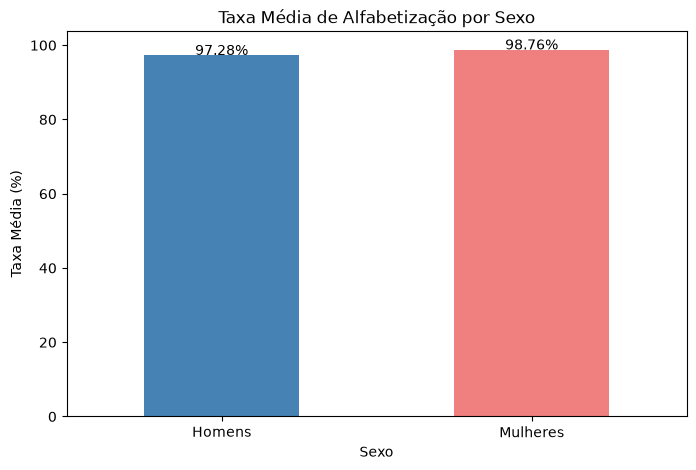

In [25]:
import matplotlib.pyplot as plt

media_sexo = (
    df_final
    .groupby('sexo')['taxa_alfabetizacao']
    .mean()
    .round(2)
)

plt.figure(figsize=(8,5))

media_sexo.plot(
    kind='bar',
    color=['steelblue', 'lightcoral']
)

plt.title('Taxa Média de Alfabetização por Sexo')
plt.xlabel('Sexo')
plt.ylabel('Taxa Média (%)')
plt.xticks(rotation=0)

for i, valor in enumerate(media_sexo):
    plt.text(i, valor + 0.1, f'{valor:.2f}%', ha='center')

plt.show()


In [26]:
#Resposta 2:
analise_raca = (
    df_final
    .groupby('cor_raca')['taxa_alfabetizacao']
    .agg([
        'count',
        'mean',
        'median',
        'std',
        'min',
        'max'
    ])
    .round(2)
)
analise_raca

,count,mean,median,std,min,max
cor_raca,,,,,,
Branca,11117,98.18,100.0,3.73,50.0,100.0
Preta,9592,97.82,100.0,6.31,25.0,100.0


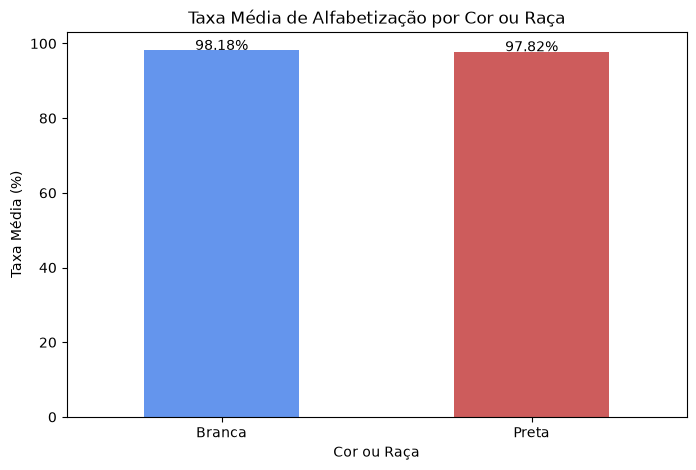

In [27]:
import matplotlib.pyplot as plt

media_raca = (
    df_final
    .groupby('cor_raca')['taxa_alfabetizacao']
    .mean()
    .round(2)
)

plt.figure(figsize=(8,5))

media_raca.plot(
    kind='bar',
    color=['cornflowerblue', 'indianred']
)

plt.title('Taxa Média de Alfabetização por Cor ou Raça')
plt.xlabel('Cor ou Raça')
plt.ylabel('Taxa Média (%)')
plt.xticks(rotation=0)

for i, valor in enumerate(media_raca):
    plt.text(i, valor + 0.1, f'{valor:.2f}%', ha='center')

plt.show()

In [28]:
#Resposta  3:
analise_regiao = (
    df_final
    .groupby('regiao')['taxa_alfabetizacao']
    .agg([
        'count',
        'mean',
        'median',
        'std',
        'min',
        'max'
    ])
    .round(2)
    .sort_values(by='mean', ascending=False)
)

analise_regiao

,count,mean,median,std,min,max
regiao,,,,,,
Sul,3899,99.03,100.0,3.37,33.33,100.0
Centro-Oeste,1743,98.74,100.0,4.36,50.00,100.0
Sudeste,6341,98.74,100.0,4.11,50.00,100.0
Norte,1752,97.51,100.0,5.40,33.33,100.0
Nordeste,6974,96.74,100.0,6.35,25.00,100.0


C:\Users\Usuário\AppData\Local\Temp\ipykernel_12520\1470359041.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


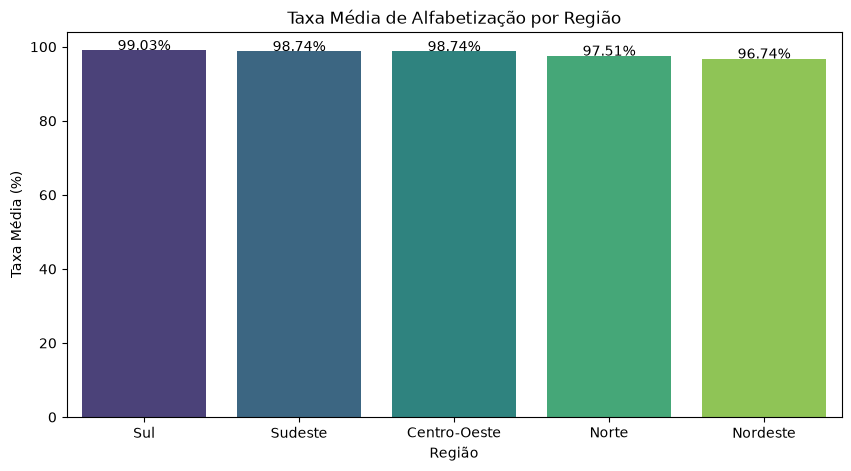

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

media_regiao = (
    df_final
    .groupby('regiao')['taxa_alfabetizacao']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,5))

sns.barplot(
    x=media_regiao.index,
    y=media_regiao.values,
    palette='viridis'
)

plt.title('Taxa Média de Alfabetização por Região')
plt.xlabel('Região')
plt.ylabel('Taxa Média (%)')

for i, valor in enumerate(media_regiao.values):
    plt.text(i, valor + 0.1, f'{valor:.2f}%', ha='center')

plt.show()

In [44]:
#Resposta 4:
tabela_regioes = pd.DataFrame({
    'uf_sigla': [
        'AC','AL','AP','AM','BA','CE','DF','ES','GO',
        'MA','MT','MS','MG','PA','PB','PR','PE','PI',
        'RJ','RN','RS','RO','RR','SC','SP','SE','TO'
    ],
    'macro_regiao': [
        'Norte','Nordeste','Norte','Norte','Nordeste','Nordeste',
        'Centro-Oeste','Sudeste','Centro-Oeste',
        'Nordeste','Centro-Oeste','Centro-Oeste','Sudeste',
        'Norte','Nordeste','Sul','Nordeste','Nordeste',
        'Sudeste','Nordeste','Sul','Norte','Norte','Sul',
        'Sudeste','Nordeste','Norte'
    ]
})

In [47]:
linhas_antes = len(df_final)

df_merge = df_final.merge(
    tabela_regioes,
    on='uf_sigla',
    how='left'
)

linhas_depois = len(df_merge)

print(f'Linhas antes do merge: {linhas_antes}')
print(f'Linhas depois do merge: {linhas_depois}')

Linhas antes do merge: 20709
Linhas depois do merge: 20709


In [48]:
ranking_estados = (
    df_merge
    .groupby('uf_sigla')['taxa_alfabetizacao']
    .agg([
        'count',
        'mean',
        'median',
        'std'
    ])
    .round(2)
    .sort_values(by='mean', ascending=False)
)

ranking_estados

,count,mean,median,std
uf_sigla,,,,
SC,951,99.28,100.00,2.41
DF,4,99.24,99.28,0.29
PR,1402,99.04,100.00,3.60
RR,56,99.01,100.00,2.47
RO,203,98.96,100.00,2.95
SP,2403,98.95,100.00,3.53
RJ,368,98.86,99.74,2.16
RS,1546,98.85,100.00,3.65
MT,539,98.85,100.00,4.25


C:\Users\Usuário\AppData\Local\Temp\ipykernel_12520\1863479350.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


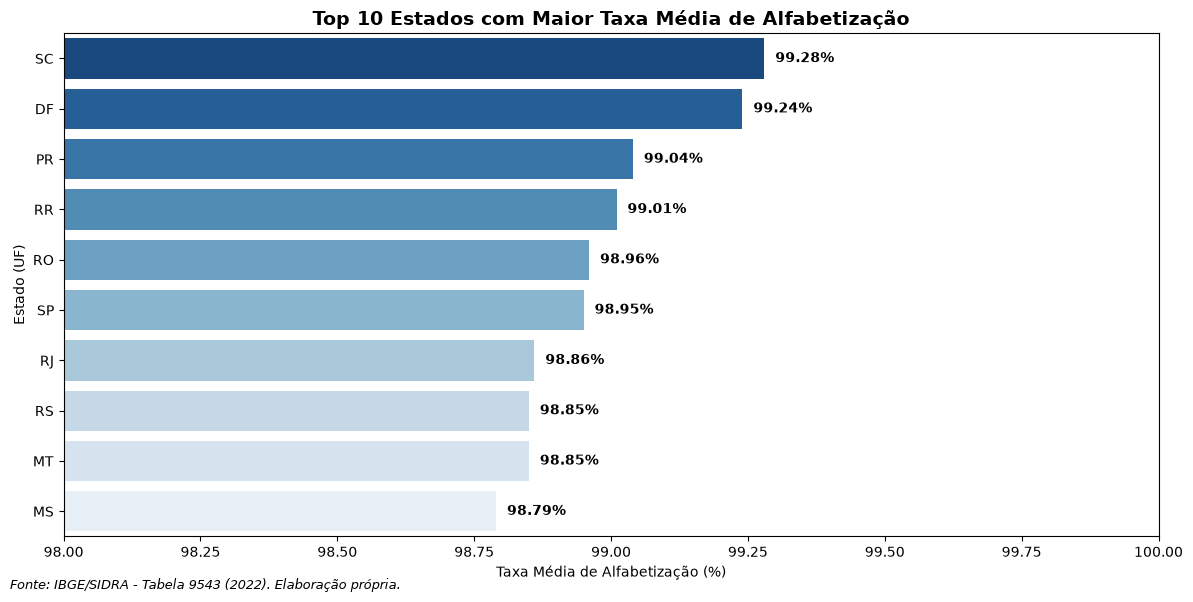

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

# Top 10 estados
top10 = ranking_estados['mean'].head(10)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    x=top10.values,
    y=top10.index,
    palette='Blues_r'
)

plt.title(
    'Top 10 Estados com Maior Taxa Média de Alfabetização',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Taxa Média de Alfabetização (%)')
plt.ylabel('Estado (UF)')

# Valores nas barras
for i, valor in enumerate(top10.values):
    ax.text(
        valor + 0.02,
        i,
        f'{valor:.2f}%',
        va='center',
        fontweight='bold'
    )

# Fonte
plt.figtext(
    0.01,
    0.01,
    'Fonte: IBGE/SIDRA - Tabela 9543 (2022). Elaboração própria.',
    fontsize=9,
    style='italic'
)

plt.xlim(98, 100)
plt.tight_layout()
plt.show()

In [50]:
#Resposta 5:
pivot_criticos = pd.pivot_table(
    grupos_criticos,
    values='quantidade',
    index='regiao',
    columns='cor_raca',
    aggfunc='sum',
    fill_value=0
)

pivot_criticos

cor_raca,Branca,Preta
regiao,,
Centro-Oeste,2,3
Nordeste,3,25
Norte,0,3
Sudeste,2,10
Sul,0,6


In [51]:
grupos_criticos = (
    df_final[df_final['faixa_alfabetizacao'] == 'Crítico (0-50%)']
    .groupby(['regiao', 'sexo', 'cor_raca'])
    .size()
    .reset_index(name='quantidade')
    .sort_values('quantidade', ascending=False)
)

grupos_criticos

,regiao,sexo,cor_raca,quantidade
4,Nordeste,Homens,Preta,17
7,Sudeste,Homens,Preta,10
5,Nordeste,Mulheres,Preta,8
9,Sul,Homens,Preta,5
1,Centro-Oeste,Homens,Preta,3
3,Nordeste,Homens,Branca,3
6,Norte,Homens,Preta,3
8,Sudeste,Mulheres,Branca,2
0,Centro-Oeste,Homens,Branca,1
2,Centro-Oeste,Mulheres,Branca,1


C:\Users\Usuário\AppData\Local\Temp\ipykernel_12520\2968752397.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


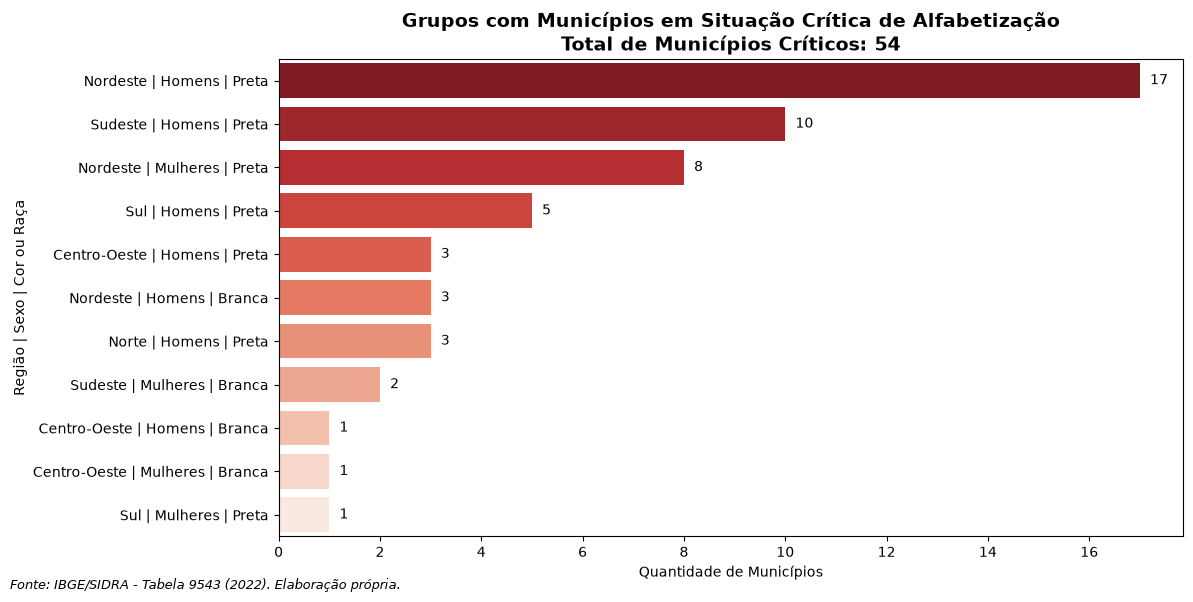

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# Cria a identificação do grupo
grupos_criticos['grupo'] = (
    grupos_criticos['regiao'] + ' | ' +
    grupos_criticos['sexo'] + ' | ' +
    grupos_criticos['cor_raca']
)

# Total de municípios críticos
total_criticos = grupos_criticos['quantidade'].sum()

plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=grupos_criticos,
    x='quantidade',
    y='grupo',
    palette='Reds_r'
)

plt.title(
    f'Grupos com Municípios em Situação Crítica de Alfabetização\n'
    f'Total de Municípios Críticos: {total_criticos}',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Quantidade de Municípios')
plt.ylabel('Região | Sexo | Cor ou Raça')

# Valores nas barras
for i, valor in enumerate(grupos_criticos['quantidade']):
    ax.text(valor + 0.2, i, str(valor), va='center')

# Fonte
plt.figtext(
    0.01,
    0.01,
    'Fonte: IBGE/SIDRA - Tabela 9543 (2022). Elaboração própria.',
    fontsize=9,
    style='italic'
)

plt.tight_layout()
plt.show()